In [11]:
import duckdb
import pandas as pd
import numpy as np

from pathlib import Path

DB_PATH = (
    Path.cwd().resolve().parent
    / "warehouse"
    / "imdb_analytics"
    / "dev.duckdb"
)

con = duckdb.connect(str(DB_PATH), read_only=True)

print("Connexion DuckDB réussie !")

Connexion DuckDB réussie !


In [12]:
#Étape 2 — Extraire les données IMDb

query = """
SELECT
    f.tconst,
    f.annee,
    f.duree_minutes,
    f.note_moyenne,
    d.titre,
    STRING_AGG(
        DISTINCT g.nom_genre, ','
    ) AS genres

FROM main.fait_film f

INNER JOIN main.dim_film d
    ON f.tconst = d.tconst

LEFT JOIN main.pont_film_genre p
    ON f.tconst = p.tconst

LEFT JOIN main.dim_genre g
    ON p.genre_key = g.genre_key

WHERE f.note_moyenne IS NOT NULL
  AND f.annee IS NOT NULL
  AND f.duree_minutes IS NOT NULL
  AND f.duree_minutes > 0
  AND f.annee <= 2026

GROUP BY
    f.tconst,
    f.annee,
    f.duree_minutes,
    f.note_moyenne,
    d.titre
"""

df = con.execute(query).df()

print("Extraction terminée !")
print("Nombre de films :", len(df))

display(df.head(10))


Extraction terminée !
Nombre de films : 321958


,tconst,annee,duree_minutes,note_moyenne,titre,genres
0,tt5441674,2016,80,6.2,Tiempo sin pulso,"Family,Romance,Drama"
1,tt5462694,1997,104,5.5,Ionopsis,"Sci-Fi,Fantasy,Adventure"
2,tt5596030,1976,75,3.5,Eksik Etek,"Comedy,Romance"
3,tt6243826,2017,85,7.3,The Good Intentions,"Biography,Documentary,Comedy"
4,tt6411954,2018,80,4.7,Anonymous 616,"Mystery,Horror,Thriller"
5,tt6907856,2017,92,6.6,Baracas: Barisan Anti Cinta Asmara,"Drama,Comedy"
6,tt0453582,2005,136,5.3,7 1/2 Phere: More Than a Wedding,"Comedy,Drama"
7,tt0483034,2004,76,7.3,Letters from Karelia,"History,Documentary"
8,tt0498341,2006,95,5.4,The Enigma with a Stigma,Comedy
9,tt0757181,1932,83,6.5,The Congress Dances,"History,Comedy,Musical"


In [13]:

# ÉTAPE 3 : QUALITÉ DES DONNÉES: vérification des valeurs manquantes 

print("Dimensions du dataset :", df.shape)

print("\nValeurs manquantes :")
print(df.isnull().sum())

print("\nStatistiques descriptives :")
display(
    df[
        ["annee", "duree_minutes", "note_moyenne"]
    ].describe()
)


Dimensions du dataset : (321958, 6)

Valeurs manquantes :
tconst              0
annee               0
duree_minutes       0
note_moyenne        0
titre               0
genres           7024
dtype: int64

Statistiques descriptives :


,annee,duree_minutes,note_moyenne
count,321958.000000,321958.000000,321958.000000
mean,1998.129275,94.478156,6.134331
std,26.152631,135.627488,1.353366
min,1894.000000,1.000000,1.000000
25%,1982.000000,80.000000,5.300000
50%,2009.000000,91.000000,6.200000
75%,2018.000000,104.000000,7.000000
max,2026.000000,51420.000000,10.000000


In [14]:

# ÉTAPE 4 : NETTOYAGE DES DONNÉES

df_ml = df.copy()

# Remplacer les genres manquants
df_ml["genres"] = df_ml["genres"].fillna("Unknown")

# Transformer les durées pour réduire
# l'influence des valeurs extrêmement élevées
df_ml["duree_log"] = np.log1p(
    df_ml["duree_minutes"]
)

# Vérifier le nettoyage
print("Nombre de films :", len(df_ml))

print("\nValeurs manquantes :")
print(df_ml.isnull().sum())

display(df_ml.head())


Nombre de films : 321958

Valeurs manquantes :
tconst           0
annee            0
duree_minutes    0
note_moyenne     0
titre            0
genres           0
duree_log        0
dtype: int64


,tconst,annee,duree_minutes,note_moyenne,titre,genres,duree_log
0,tt5441674,2016,80,6.2,Tiempo sin pulso,"Family,Romance,Drama",4.394449
1,tt5462694,1997,104,5.5,Ionopsis,"Sci-Fi,Fantasy,Adventure",4.653960
2,tt5596030,1976,75,3.5,Eksik Etek,"Comedy,Romance",4.330733
3,tt6243826,2017,85,7.3,The Good Intentions,"Biography,Documentary,Comedy",4.454347
4,tt6411954,2018,80,4.7,Anonymous 616,"Mystery,Horror,Thriller",4.394449


In [15]:

# ÉTAPE 5 : ENCODAGE DES GENRES

from sklearn.preprocessing import MultiLabelBinarizer

# Convertir les genres en listes
genres_listes = df_ml["genres"].apply(
    lambda x: x.split(",")
)

# Encoder chaque genre en colonne
mlb = MultiLabelBinarizer()

genres_encodes = pd.DataFrame(
    mlb.fit_transform(genres_listes),
    columns=[
        "genre_" + genre
        for genre in mlb.classes_
    ],
    index=df_ml.index
)

# Construire le dataset final
X = pd.concat(
    [
        df_ml[["annee", "duree_log"]],
        genres_encodes
    ],
    axis=1
)

y = df_ml["note_moyenne"]

print("Dimensions X :", X.shape)
print("Dimensions y :", y.shape)

display(X.head())


Dimensions X : (321958, 30)
Dimensions y : (321958,)


,annee,duree_log,genre_Action,genre_Adult,genre_Adventure,genre_Animation,genre_Biography,genre_Comedy,genre_Crime,genre_Documentary,...,genre_News,genre_Reality-TV,genre_Romance,genre_Sci-Fi,genre_Sport,genre_Talk-Show,genre_Thriller,genre_Unknown,genre_War,genre_Western
0,2016,4.394449,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
1,1997,4.653960,0,0,1,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
2,1976,4.330733,0,0,0,0,0,1,0,0,...,0,0,1,0,0,0,0,0,0,0
3,2017,4.454347,0,0,0,0,1,1,0,1,...,0,0,0,0,0,0,0,0,0,0
4,2018,4.394449,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0


In [16]:

# ÉTAPE 6 : DÉCOUPAGE TEMPOREL

# Films avant 2015 : entraînement
train_mask = df_ml["annee"] < 2015

# Films à partir de 2015 : test
test_mask = df_ml["annee"] >= 2015

X_train = X.loc[train_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

print("Films d'entraînement :", len(X_train))
print("Films de test :", len(X_test))

print("Année maximale entraînement :",
      df_ml.loc[train_mask, "annee"].max())

print("Année minimale test :",
      df_ml.loc[test_mask, "annee"].min())


Films d'entraînement : 205635
Films de test : 116323
Année maximale entraînement : 2014
Année minimale test : 2015


In [17]:

# ÉTAPE 7 : BASELINE : Créer un modèle de référence

from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error,
    r2_score
)

baseline = DummyRegressor(strategy="mean")

baseline.fit(X_train, y_train)

pred_baseline = baseline.predict(X_test)

mae_baseline = mean_absolute_error(
    y_test, pred_baseline
)

r2_baseline = r2_score(
    y_test, pred_baseline
)

print("===== BASELINE =====")
print("MAE :", round(mae_baseline, 4))
print("R² :", round(r2_baseline, 4))


===== BASELINE =====
MAE : 1.214
R² : -0.0049


In [18]:

# ÉTAPE 8 : Entrainement du modèle RANDOM FOREST

from sklearn.ensemble import RandomForestRegressor

# Échantillon d'entraînement reproductible
X_train_sample = X_train.sample(
    n=min(50000, len(X_train)),
    random_state=42
)

y_train_sample = y_train.loc[
    X_train_sample.index
]

modele_rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

modele_rf.fit(
    X_train_sample,
    y_train_sample
)

pred_rf = modele_rf.predict(X_test)

mae_rf = mean_absolute_error(
    y_test,
    pred_rf
)

r2_rf = r2_score(
    y_test,
    pred_rf
)

print("===== RANDOM FOREST =====")
print("MAE :", round(mae_rf, 4))
print("R² :", round(r2_rf, 4))


===== RANDOM FOREST =====
MAE : 1.0034
R² : 0.2456


In [19]:

# ÉTAPE 9 : COMPARAISON des erreurs de prédiction

comparaison = pd.DataFrame({
    "Modèle": [
        "Baseline",
        "Random Forest"
    ],
    "MAE": [
        mae_baseline,
        mae_rf
    ],
    "R²": [
        r2_baseline,
        r2_rf
    ]
})

display(comparaison.round(4))

if mae_rf < mae_baseline:
    print(
        "Random Forest améliore "
        "la prédiction par rapport à la baseline."
    )
else:
    print(
        "Random Forest ne fait pas mieux "
        "que la baseline sur cet ensemble de test."
    )


,Modèle,MAE,R²
0,Baseline,1.2140,-0.0049
1,Random Forest,1.0034,0.2456


Random Forest améliore la prédiction par rapport à la baseline.


In [21]:
%pip install matplotlib

   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   --- ------------------------------------ 0.8/9.3 MB 1.8 MB/s eta 0:00:05
   ---- ----------------------------------- 1.0/9.3 MB 1.8 MB/s eta 0:00:05
   ----- ---------------------------------- 1.3/9.3 MB 1.8 MB/s eta 0:00:05
   ------- -------------------------------- 1.8/9.3 MB 1.8 MB/s eta 0:00:05
   -------- ------------------------------- 2.1/9.3 MB 1.8 MB/s eta 0:00:05
   ----------- ---------------------------- 2.6/9.3 MB 1.8 MB/s eta 0:00:04
   ------------ --------------------------- 2.9/9.3 MB 1.8 MB/s eta 0:00:04
   ------------- -------------------------- 3.1/9.3 MB 1.8 MB/s eta 0:00:04
   --------------- ------------------------ 3.7/9.3 MB 1.9 MB/s eta 0:00:04
   ----------------- ---------------------- 4.2/9.3 MB 1.9 MB/s eta 0:00:03
   -------------------- ------------------- 4.7/9.3 MB 1.9 MB/s eta 0:00:03
   --------------------- -

In [22]:
import matplotlib
import matplotlib.pyplot as plt

print("Matplotlib installé :", matplotlib.__version__)

Matplotlib installé : 3.11.2


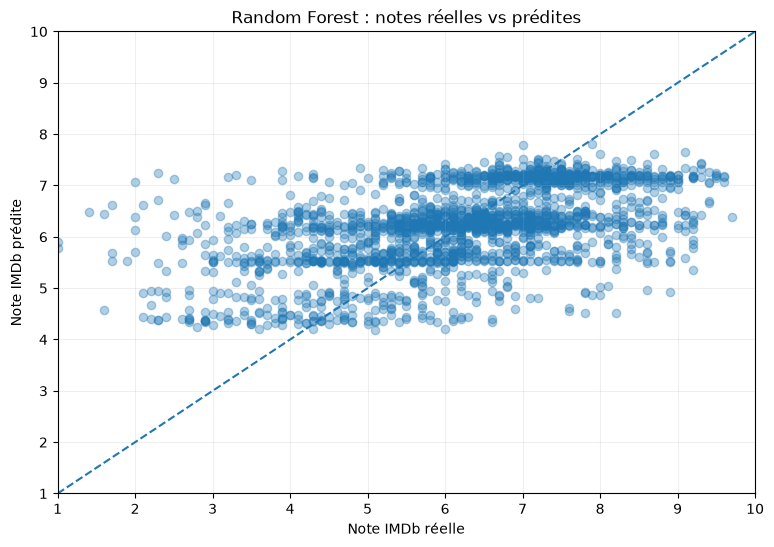

In [23]:
import matplotlib.pyplot as plt

resultats = pd.DataFrame({
    "Note réelle": y_test.to_numpy(),
    "Note prédite": pred_rf
})

echantillon = resultats.sample(
    n=min(2000, len(resultats)),
    random_state=42
)

plt.figure(figsize=(9, 6))

plt.scatter(
    echantillon["Note réelle"],
    echantillon["Note prédite"],
    alpha=0.35
)

plt.plot(
    [1, 10],
    [1, 10],
    linestyle="--"
)

plt.xlabel("Note IMDb réelle")
plt.ylabel("Note IMDb prédite")
plt.title("Random Forest : notes réelles vs prédites")

plt.xlim(1, 10)
plt.ylim(1, 10)
plt.grid(alpha=0.2)

plt.show()

,Variable,Importance
9,genre_Documentary,0.347607
1,duree_log,0.213634
0,annee,0.155643
16,genre_Horror,0.120994
10,genre_Drama,0.051244
2,genre_Action,0.017851
5,genre_Animation,0.011148
7,genre_Comedy,0.009661
26,genre_Thriller,0.007397
23,genre_Sci-Fi,0.006984


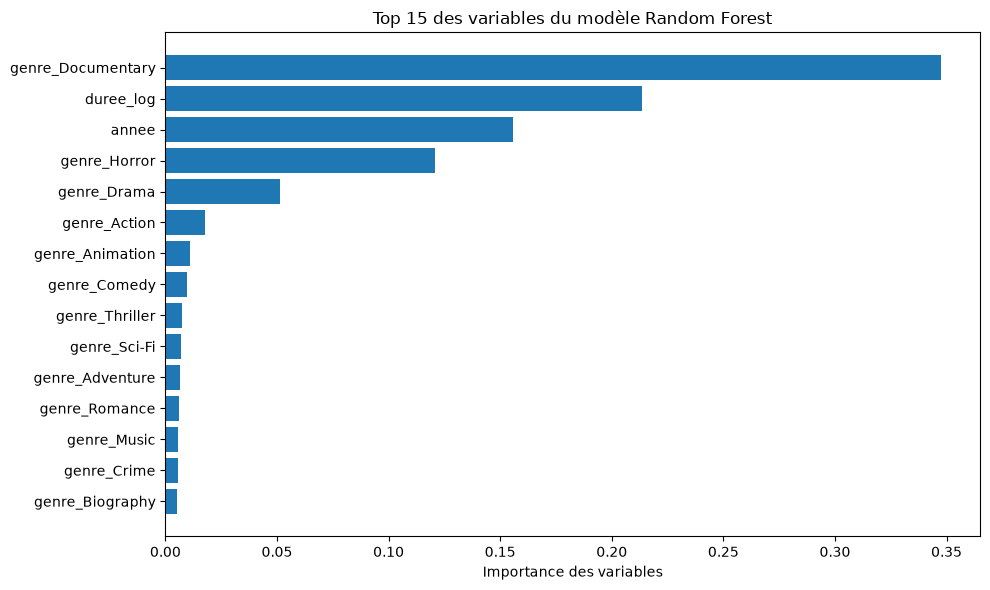

In [24]:

# ÉTAPE 11 : IMPORTANCE DES VARIABLES

importances = pd.DataFrame({
    "Variable": X_train.columns,
    "Importance": modele_rf.feature_importances_
})

importances = importances.sort_values(
    by="Importance",
    ascending=False
)

display(importances.head(15))

# Visualisation
top_variables = importances.head(15).sort_values(
    "Importance"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_variables["Variable"],
    top_variables["Importance"]
)

plt.xlabel("Importance des variables")
plt.title("Top 15 des variables du modèle Random Forest")
plt.tight_layout()
plt.show()


In [25]:

# ÉTAPE 12 : SAUVEGARDE DU MODÈLE

import joblib
from pathlib import Path

# Localiser la racine du projet
dossier = Path.cwd().resolve()

if (dossier / "warehouse").exists():
    BASE_DIR = dossier
else:
    BASE_DIR = dossier.parent

# Créer le dossier models_ml
MODEL_DIR = BASE_DIR / "models_ml"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Enregistrer le modèle et sa configuration
artefact = {
    "model": modele_rf,
    "features": X_train.columns.tolist(),
    "genres": mlb.classes_.tolist(),
    "annee_min": int(df_ml["annee"].min()),
    "annee_max": int(df_ml["annee"].max()),
    "mae_test": float(mae_rf),
    "r2_test": float(r2_rf)
}

joblib.dump(
    artefact,
    MODEL_DIR / "modele_imdb.pkl"
)

print("Modèle enregistré avec succès !")
print(MODEL_DIR / "modele_imdb.pkl")


Modèle enregistré avec succès !
C:\Users\Aya\Desktop\projet_BISirine\models_ml\modele_imdb.pkl
